In [1]:
import pandas as pd
from datetime import datetime
from pathlib import Path
import geopandas as gpd

from benchmark_pipeline.generator.features import *
from benchmark_pipeline.loader.osm_loaders import load_pois, load_area, load_streets
from benchmark_pipeline.generator.template_question.semantic.generetor_qsemantic import make_questions_semantic
from benchmark_pipeline.config import FEATURES
from benchmark_pipeline.generator.template_question.composite.generator_qcomposite import make_question_composite
from benchmark_pipeline.generator.targets.mask_anchors import add_anchors_mask
from benchmark_pipeline.generator.targets.ellypses import add_ellypse
from benchmark_pipeline.generator.targets.anchors import add_anchors
from benchmark_pipeline.generator.template_question.register import register, BenchmarkConfig
from benchmark_pipeline.generator.template_question.composite.format_samples import format_composit_samples
from benchmark_pipeline.path import DATA
from benchmark_pipeline.dataviz_tools.question_viz import montrer_questions
#from benchmark_pipeline.paraphrase import  make_paraphrase
#from gseek.models.sentence_encoder import SentenceEncoder

In [2]:
register_path = "/Users/sese/Documents/code/Gseek/demo_data/"

list_template = ['make_question_area_border',
                 'make_question_area_inside', 'make_question_area_direction',
                 'make_question_point_between', 'make_question_point_near_cardinal',
                 'make_question_point_near_metric', 'make_question_point_near',
                 'make_question_point_towards', 'make_question_street_along',
                 'make_question_street_cross'] #'make_question_area_outside', 'make_question_street_opposite_side',

In [3]:
def disambiguate_names(
        df_osm,
        df_street,
        df_area
    ):
    for _, poi_row in df_osm.iterrows():
        matches = df_street[df_street["street_name"] == poi_row["poi_name"]]
        for street_label, street_row in matches.iterrows():
            street_name = street_row["street_name"]
            if "Rue" not in street_name:
                df_street.at[street_label, "street_name"] = f"Rue {street_name}"

        area_similarity = df_area[df_area["area_name"]==poi_row["poi_name"]]
        for area_num_row, area_row in area_similarity.iterrows():
            area_name = area_row["area_name"]
            area_category = area_row["category"]
            df_area.at[area_num_row, "area_name"] = f"{area_category} {area_name}"

    return df_osm, df_street, df_area

In [4]:
df_osm = load_pois()
df_street = load_streets()
df_area = load_area()

/Users/sese/Documents/code/benchmark_pipeline/benchmark_pipeline/loader/osm_extractor.py:129: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  pois["geometry"] = pois.geometry.centroid


In [5]:
df_osm_clean, df_street_clean, df_area_clean = disambiguate_names(df_osm, df_street, df_area)

In [7]:
"""
Création du dataframe de questions
"""
df_question = make_question_composite(
        df_osm_clean, 
        df_area_clean,
        df_street_clean, 
        nb_q_by_temp=100, 
        nb_q_by_feat=100, 
        feature_cols=FEATURES,
        seed=42,
    )

#data= make_paraphrase(df_question_test, nb_generated=10)
"""On ajout eles cibles pour entrainer le modele, c'est inutile si on n'entraine pas Gseek dessus, A mettre dans Gseek """

is_gseek_training = False
if is_gseek_training:
    #sentence_model = SentenceEncoder()
    #df_question = add_anchors_mask(df_question, sentence_model)
    df_question = add_ellypse(df_question)
    df_question = add_anchors(df_question)

#df_question = df_question.rename(columns={"pois": "results_poi_id"})
conf = BenchmarkConfig(
        ratio_test = 0.1,
        ratio_features = None, #{1: 0.4, 2: 0.4, 3: 0.2}, 
        ratio_category= None,
        rows_target = [],#["mask_token_anchors", "ellypse", "anchors_type_target"],
        nb_hard = 20,
        nb_unmatches = 1,
        seed = 42,
    )

register(DATA / "benchmark_1K_after_correctionbug", df_question, df_osm_clean, df_street_clean, df_area_clean, conf, format_composit_samples, overwritte=True)

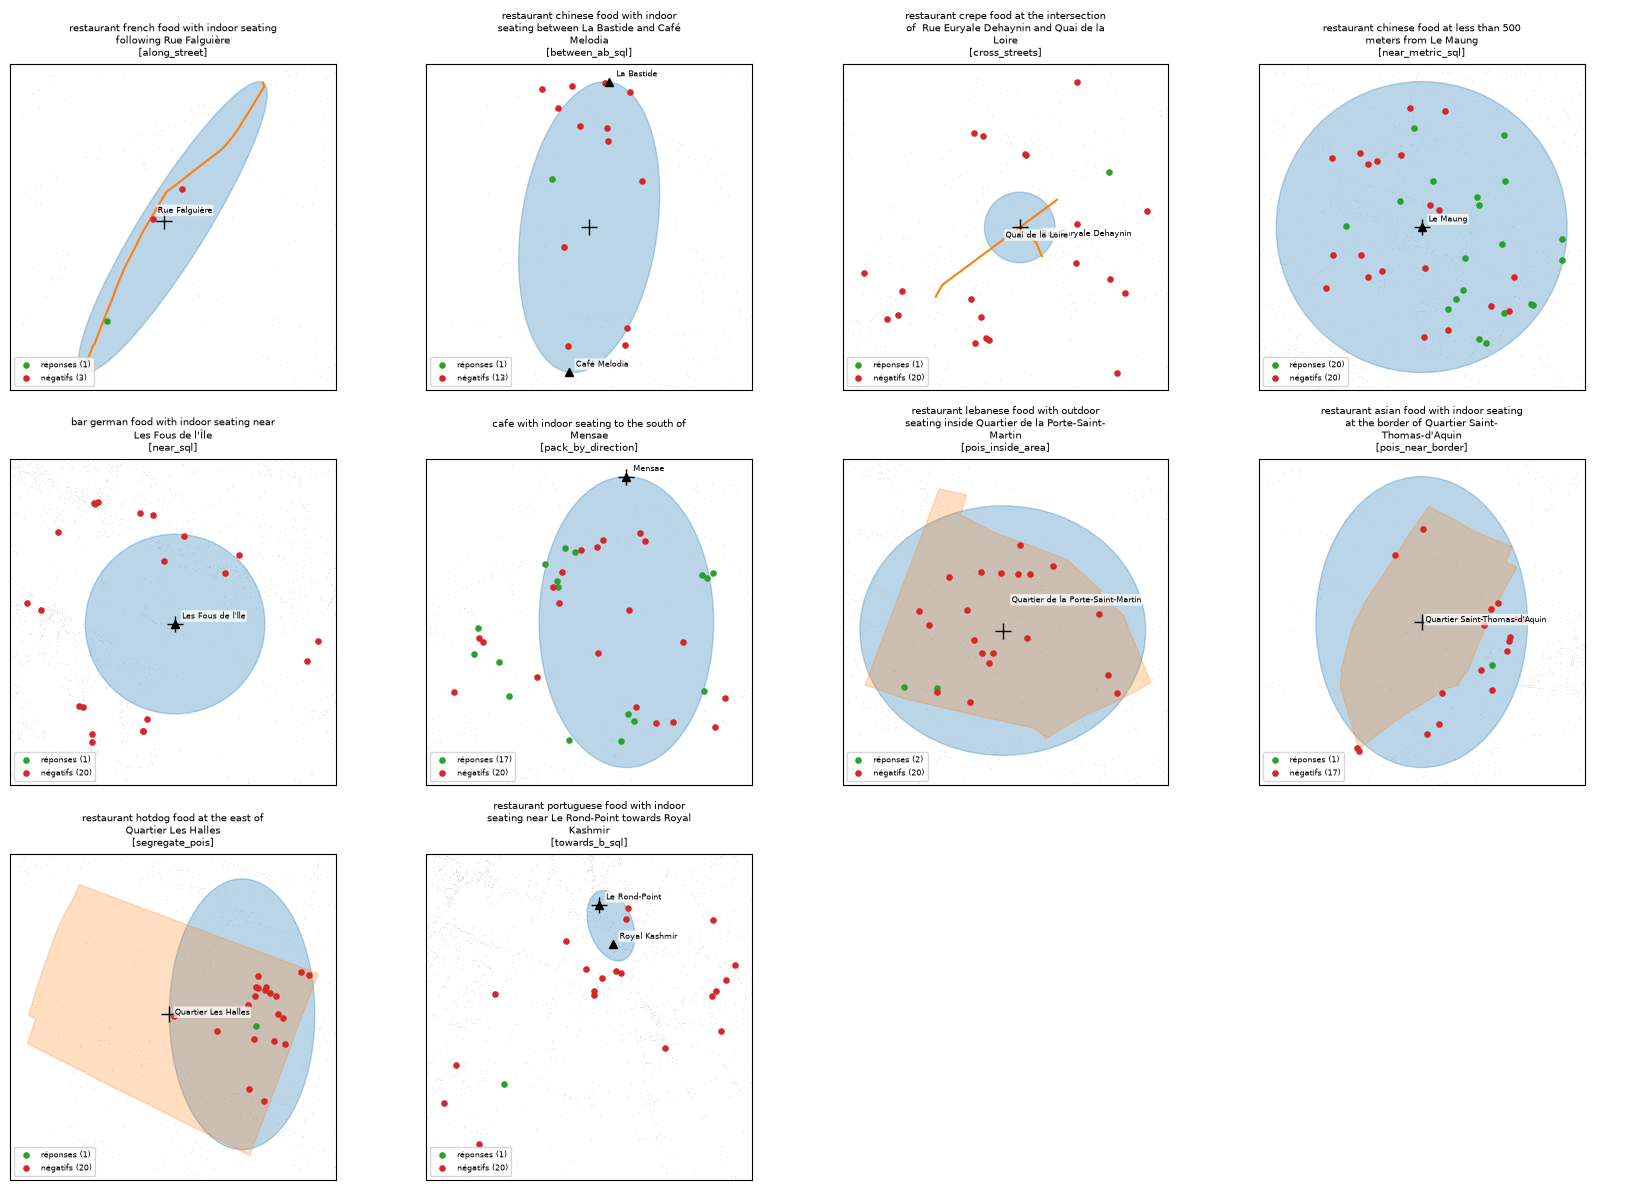

In [ ]:
montrer_questions(df_question, df_osm, par_type=True)